In [1]:
import time
start_time = time.time()

## Step 1: The Sample Space and the Axioms


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from mp1lib import attempts_until_clean

SEED = 69420
rng = np.random.default_rng(SEED)
rng_step1 = rng.spawn(1)[0]


In [3]:
p = 0.1
n_bits = 4
N = 10**6

In [4]:
from mp1lib import bsc

bits = np.array([0, 1, 0, 1])
result = bsc(bits, 0, rng_step1)

print("Original:", bits)
print("Output:", result)

Original: [0 1 0 1]
Output: [0 1 0 1]


In [5]:
from itertools import product

patterns = np.array(list(product([0, 1], repeat=n_bits)))
probabilities = np.array([
    p**sum(pattern) * (1-p)**(n_bits-sum(pattern))
    for pattern in patterns
])

for pattern, prob in zip(patterns, probabilities):
    print("".join(map(str, pattern)), f"{prob:.6f}")

print("Total probability:", probabilities.sum())

0000 0.656100
0001 0.072900
0010 0.072900
0011 0.008100
0100 0.072900
0101 0.008100
0110 0.008100
0111 0.000900
1000 0.072900
1001 0.008100
1010 0.008100
1011 0.000900
1100 0.008100
1101 0.000900
1110 0.000900
1111 0.000100
Total probability: 0.9999999999999999


### Exact Event Probabilities

For a 4-bit packet with \(p = 0.1\):

**Event A: At least one error among the first two bits**

$$
P(A)=1-P(\text{no errors in first two bits})
$$

$$
P(A)=1-(1-p)^2=1-(0.9)^2=\boxed{0.19}
$$

**Event B: Exactly two errors in the packet**

$$
P(B)=\binom{4}{2}p^2(1-p)^2
$$

$$
P(B)=6(0.1)^2(0.9)^2=\boxed{0.0486}
$$

**Event C: The fourth bit is in error**

$$
P(C)=p=\boxed{0.1}
$$

### Exact Intersection Probabilities

**Intersection of A and B**

Exactly two errors, with at least one in the first two bits:

$$
P(A\cap B)=\left[\binom{4}{2}-\binom{2}{2}\right]p^2(1-p)^2
$$

$$
P(A\cap B)=5(0.1)^2(0.9)^2=0.0405
$$

**Intersection of A and C**

The fourth bit and at least one of the first two bits are in error:

$$
P(A\cap C)=P(A)P(C)
$$

$$
P(A\cap C)=0.19(0.1)=0.019
$$

**Intersection of B and C**

Exactly two errors, including the fourth bit:

$$
P(B\cap C)=\binom{3}{1}p^2(1-p)^2
$$

$$
P(B\cap C)=3(0.1)^2(0.9)^2=0.0243
$$

**Triple Intersection**

Exactly two errors, including the fourth bit and one of the first two bits:

$$
P(A\cap B\cap C)=2p^2(1-p)^2
$$

$$
P(A\cap B\cap C)=2(0.1)^2(0.9)^2=0.0162
$$

### Inclusion-Exclusion

Using the inclusion-exclusion formula:

$$
P(A\cup B\cup C)=P(A)+P(B)+P(C)-P(A\cap B)-P(A\cap C)-P(B\cap C)+P(A\cap B\cap C)
$$

Substituting the calculated probabilities:

$$
P(A\cup B\cup C)=0.19+0.0486+0.1-0.0405-0.019-0.0243+0.0162
$$

$$
\boxed{P(A\cup B\cup C)=0.2710}
$$

In [6]:

errors = rng_step1.random((N, n_bits)) < p

A = errors[:, 0] | errors[:, 1]
B = errors.sum(axis=1) == 2
C = errors[:, 3]

print("P(A):", A.mean())
print("P(B):", B.mean())
print("P(C):", C.mean())


P(A): 0.189944
P(B): 0.04842
P(C): 0.1002


In [7]:

AB = A & B
AC = A & C
BC = B & C
ABC = A & B & C

print("P(A and B):", AB.mean())
print("P(A and C):", AC.mean())
print("P(B and C):", BC.mean())
print("P(A and B and C):", ABC.mean())


P(A and B): 0.040197
P(A and C): 0.018952
P(B and C): 0.024332
P(A and B and C): 0.016109


In [8]:

union = A | B | C

p_union = A.mean() + B.mean() + C.mean() - AB.mean() - AC.mean() - BC.mean() + ABC.mean()

print("Exact P(A or B or C):", 0.2710)
print("Simulated P(A or B or C):", union.mean())
print("Inclusion-Exclusion:", p_union)
print("Difference:", abs(union.mean() - 0.2710))


Exact P(A or B or C): 0.271
Simulated P(A or B or C): 0.271192
Inclusion-Exclusion: 0.27119199999999993
Difference: 0.00019199999999996997


In [9]:

exact = np.array([0.19, 0.0486, 0.1, 0.0405, 0.019, 0.0243, 0.0162, 0.2710])

simulated = np.array([A.mean(), B.mean(), C.mean(), AB.mean(), AC.mean(), BC.mean(), ABC.mean(), union.mean()])

names = ["A", "B", "C", "A and B", "A and C", "B and C", "A and B and C", "A or B or C"]

se = np.sqrt(exact * (1 - exact) / N)

for name, e, s, error in zip(names, exact, simulated, se):
    diff = abs(e - s)
    print(f"{name}: Exact={e:.6f}, Simulated={s:.6f}, Difference={diff:.6f}, SE={error:.6f}, Within 3 SE={diff <= 3*error}")


A: Exact=0.190000, Simulated=0.189944, Difference=0.000056, SE=0.000392, Within 3 SE=True
B: Exact=0.048600, Simulated=0.048420, Difference=0.000180, SE=0.000215, Within 3 SE=True
C: Exact=0.100000, Simulated=0.100200, Difference=0.000200, SE=0.000300, Within 3 SE=True
A and B: Exact=0.040500, Simulated=0.040197, Difference=0.000303, SE=0.000197, Within 3 SE=True
A and C: Exact=0.019000, Simulated=0.018952, Difference=0.000048, SE=0.000137, Within 3 SE=True
B and C: Exact=0.024300, Simulated=0.024332, Difference=0.000032, SE=0.000154, Within 3 SE=True
A and B and C: Exact=0.016200, Simulated=0.016109, Difference=0.000091, SE=0.000126, Within 3 SE=True
A or B or C: Exact=0.271000, Simulated=0.271192, Difference=0.000192, SE=0.000444, Within 3 SE=True


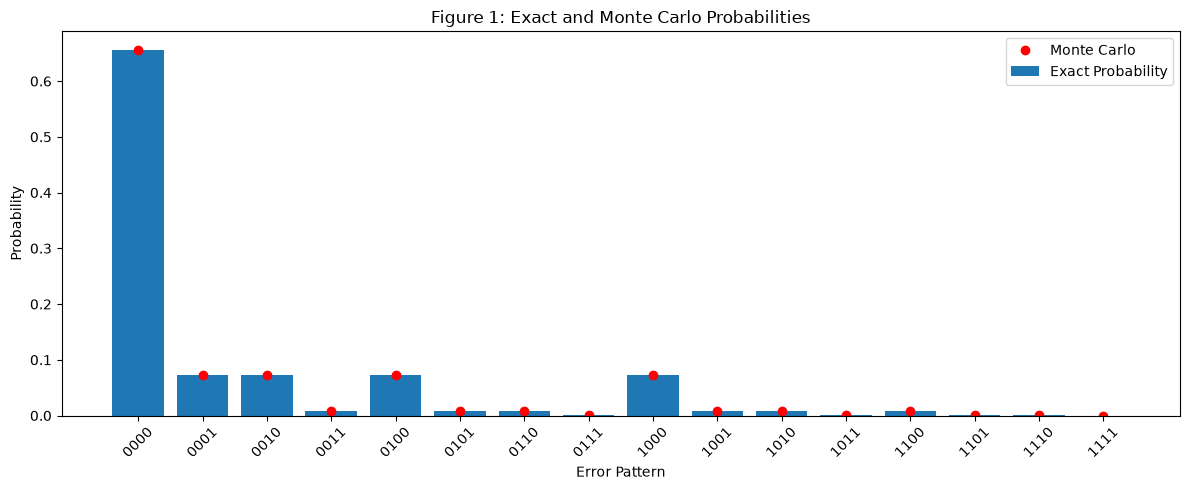

In [10]:

counts = np.array([
    np.all(errors == pattern, axis=1).sum()
    for pattern in patterns
])

empirical = counts / N
labels = ["".join(map(str, pattern)) for pattern in patterns]

plt.figure(figsize=(12, 5))
plt.bar(labels, probabilities, label="Exact Probability")
plt.plot(labels, empirical, "ro", label="Monte Carlo")

plt.xlabel("Error Pattern")
plt.ylabel("Probability")
plt.title("Figure 1: Exact and Monte Carlo Probabilities")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


A comparison of the exact probabilities for all sixteen possible error events and the Monte Carlo approximations using 1,000,000 simulated packets (each with 4 bits) having an error rate of p = .10, shows the Monte Carlo approximations were very close to the exact probabilities, as evidenced by the closeness of the red symbols to the bars representing the exact probabilities. The error pattern 0000 had the largest probability of about .6561 showing that it is most likely a packet will contain no errors. There was a probability of .0729 for those symbols with exactly one error. Those patterns that contained two or more errors had much smaller individual probabilities. The smallest probability was for the symbol 1111 which represented all four bits being in error. As each bit is independently corrupted at a probability of .10 there is a much reduced likelihood that multiple bits will be simultaneously corrupted. In general, the close correspondence of the theoretical and estimated probabilities confirms that the Monte Carlo method can simulate the behavior expected of this model.

In [11]:
print(f"{'Event':<15} {'Exact':<12} {'Simulated':<12} {'Difference':<12} {'SE':<12} {'Within 3 SE'}")

for i in range(7):
    diff = abs(exact[i] - simulated[i])
    print(f"{names[i]:<15} {exact[i]:<12.6f} {simulated[i]:<12.6f} {diff:<12.6f} {se[i]:<12.6f} {diff <= 3*se[i]}")


Event           Exact        Simulated    Difference   SE           Within 3 SE
A               0.190000     0.189944     0.000056     0.000392     True
B               0.048600     0.048420     0.000180     0.000215     True
C               0.100000     0.100200     0.000200     0.000300     True
A and B         0.040500     0.040197     0.000303     0.000197     True
A and C         0.019000     0.018952     0.000048     0.000137     True
B and C         0.024300     0.024332     0.000032     0.000154     True
A and B and C   0.016200     0.016109     0.000091     0.000126     True


The table above compares the exact theoretical probabilities with the Monte Carlo estimates obtained from 1,000,000 simulated packets. The results show that all seven estimated probabilities are very close to their corresponding theoretical values, with relatively small differences between them. The standard error was calculated for each probability estimate to determine whether the differences were within an acceptable range. All seven estimates were found to be within three standard errors of their theoretical probabilities, indicating that the differences can reasonably be attributed to random sampling variation. Overall, these results demonstrate that the Monte Carlo simulation produces reliable estimates and closely follows the expected theoretical probabilities.

## Step 2: Conditional Probability and Bayes


### Conditional Probabilities and Bayes' Theorem

The error flagging circuit has two possible outcomes: a bit is either in error or not in error. The probability that a bit is in error is \(p\), while the probability that it is not in error is \(1-p\).

The probability that the circuit flags a bit when it is actually in error is:

$$
P(F|E)=0.95
$$

The probability that the circuit flags a bit when it is not in error is:

$$
P(F|E^c)=0.02
$$

Using Bayes' theorem, the probability that a flagged bit is truly in error is:

$$
P(E|F)=\frac{P(F|E)P(E)}{P(F)}
$$

The total probability of a flag is:

$$
P(F)=P(F|E)P(E)+P(F|E^c)P(E^c)
$$

Substituting the given probabilities:

$$
P(F)=0.95p+0.02(1-p)
$$

Therefore, the posterior probability is:

$$
\boxed{P(E|F)=\frac{0.95p}{0.95p+0.02(1-p)}}
$$


In [12]:

p_values = [0.1, 0.01, 0.001]

for p in p_values:
    posterior = (0.95 * p) / (0.95 * p + 0.02 * (1 - p))
    print(f"p = {p}: P(E|F) = {posterior:.6f}")


p = 0.1: P(E|F) = 0.840708
p = 0.01: P(E|F) = 0.324232
p = 0.001: P(E|F) = 0.045389


In [13]:

rng_step2 = rng.spawn(1)[0]

N2 = 10**7
p_cross = 0.01 / 0.485

errors2 = rng_step2.random(N2) < p_cross
flags2 = rng_step2.random(N2) < np.where(errors2, 0.95, 0.02)

n_flags = flags2.sum()
posterior_sim = (errors2 & flags2).sum() / n_flags
posterior_exact = (0.95 * p_cross) / (0.95 * p_cross + 0.02 * (1 - p_cross))
se2 = np.sqrt(posterior_sim * (1 - posterior_sim) / n_flags)

print(f"Number of flags: {n_flags}")
print(f"Exact posterior: {posterior_exact:.6f}")
print(f"Simulated posterior: {posterior_sim:.6f}")
print(f"Difference: {abs(posterior_exact - posterior_sim):.6f}")
print(f"Standard error: {se2:.6f}")
print(f"Within 3 SE: {abs(posterior_exact - posterior_sim) <= 3 * se2}")


Number of flags: 391887
Exact posterior: 0.500000
Simulated posterior: 0.500598
Difference: 0.000598
Standard error: 0.000799
Within 3 SE: True


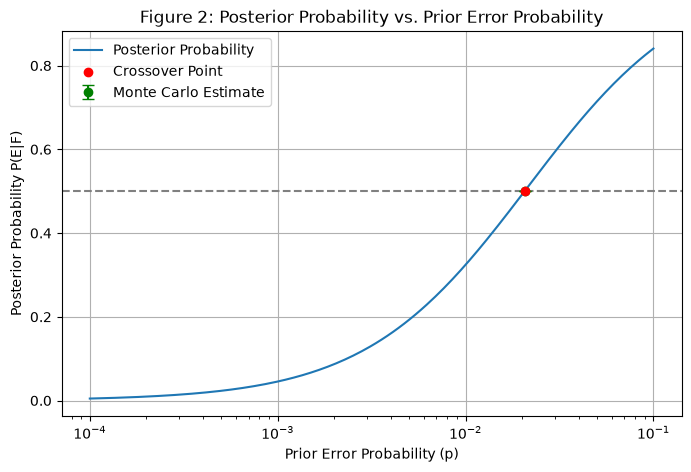

In [14]:

p_plot = np.logspace(-4, -1, 200)
posterior_plot = (0.95 * p_plot) / (0.95 * p_plot + 0.02 * (1 - p_plot))

plt.figure(figsize=(8, 5))
plt.plot(p_plot, posterior_plot, label="Posterior Probability")
plt.xscale("log")
plt.xlabel("Prior Error Probability (p)")
plt.ylabel("Posterior Probability P(E|F)")
plt.title("Figure 2: Posterior Probability vs. Prior Error Probability")
p_cross = 0.01 / 0.485
plt.scatter(p_cross, 0.5, color="red", label="Crossover Point", zorder=3)
plt.axhline(0.5, color="gray", linestyle="--")
plt.errorbar(p_cross, posterior_sim, yerr=se2, fmt="o",
             color="green", capsize=4, label="Monte Carlo Estimate")
plt.legend()
plt.grid(True)
plt.show()



### Crossover Point

The crossover point occurs when the posterior probability equals 0.5.

$$
\frac{0.95p}{0.95p+0.02(1-p)}=0.5
$$

$$
0.95p=0.5(0.95p+0.02(1-p))
$$

$$
0.95p=0.475p+0.01-0.01p
$$

$$
0.485p=0.01
$$

$$
\boxed{p=\frac{0.01}{0.485}\approx0.020619}
$$


A Monte Carlo simulation was run with 10 million bits and a crossover probability of approximately 0.020619. Of those 10 million bits, 391,887 were identified as having been flagged and therefore the simulated posterior probability was 0.500598, while the calculated posterior probability from theory for this problem was 0.500000. As such, the 0.000598 difference between theory and simulation was less than three standard errors, indicating that the simulation produced results that were consistent with the theoretical results.

Therefore, the simulation demonstrates that whether or not an error flag is reliable is dependent upon what the initial probability of a bit being in error is. For example if the probability of a bit being in error is very small (i.e., near zero) then there will likely be a smaller number of true positive error flags and as a result a larger proportion of false positives (bits identified as being in error but are not). Even so the system would have correctly identified 95% of all bits that were in error. A manager should be aware of the underlying error rate prior to making assumptions regarding how many flagged bits represent actual errors.


## Step 3: Independence

### Part 1: Pairwise and Mutual Independence

Consider two independent fair coins with the following events:

- E1: The first coin lands heads.
- E2: The second coin lands heads.
- E3: Both coins match (HH or TT).

Each coin has an equal probability of landing heads or tails. Therefore:

$$
P(E_1)=P(E_2)=P(E_3)=\frac{1}{2}
$$

For pairwise independence, the joint probability of each pair must equal the product of their individual probabilities.

$$
P(E_1\cap E_2)=P(HH)=\frac{1}{4}
=P(E_1)P(E_2)
$$

$$
P(E_1\cap E_3)=P(HH)=\frac{1}{4}
=P(E_1)P(E_3)
$$

$$
P(E_2\cap E_3)=P(HH)=\frac{1}{4}
=P(E_2)P(E_3)
$$

All three pairs are independent.

For mutual independence, the triple intersection must also equal the product of all three individual probabilities.

$$
P(E_1\cap E_2\cap E_3)=P(HH)=\frac{1}{4}
$$

$$
P(E_1)P(E_2)P(E_3)=\frac{1}{2}\cdot\frac{1}{2}\cdot\frac{1}{2}=\frac{1}{8}
$$

$$
\frac{1}{4}\neq\frac{1}{8}
$$

Therefore, the three events are pairwise independent but not mutually independent.


In [15]:

rng_step3 = rng.spawn(1)[0]

N3 = 10**6
coins = rng_step3.integers(0, 2, size=(N3, 2))

E1 = coins[:, 0] == 1
E2 = coins[:, 1] == 1
E3 = coins[:, 0] == coins[:, 1]

events = [E1, E2, E3]
pairs = [(0, 1), (0, 2), (1, 2)]

print(f"{'Events':<15} {'Joint P':<12} {'Product P':<12} {'Difference':<12}")

for i, j in pairs:
    joint = np.mean(events[i] & events[j])
    product = np.mean(events[i]) * np.mean(events[j])
    print(f"E{i+1} and E{j+1:<7} {joint:<12.6f} {product:<12.6f} {abs(joint-product):<12.6f}")

triple_joint = np.mean(E1 & E2 & E3)
triple_product = np.mean(E1) * np.mean(E2) * np.mean(E3)

print(f"{'E1 E2 E3':<15} {triple_joint:<12.6f} {triple_product:<12.6f} {abs(triple_joint-triple_product):<12.6f}")


Events          Joint P      Product P    Difference  
E1 and E2       0.249960     0.250060     0.000100    
E1 and E3       0.249960     0.250164     0.000204    
E2 and E3       0.249960     0.249696     0.000264    
E1 E2 E3        0.249960     0.124980     0.124980    


### Part 2: Conditional Independence of Two Receivers

In [16]:

N3 = 10**6

transmitted = rng_step3.integers(0, 2, N3)

error1 = rng_step3.random(N3) < 0.1
error2 = rng_step3.random(N3) < 0.3

receiver1 = transmitted ^ error1
receiver2 = transmitted ^ error2

mask0 = transmitted == 0
mask1 = transmitted == 1

def correlation_se(x, y):
    r = np.corrcoef(x, y)[0, 1]
    se = (1 - r**2) / np.sqrt(len(x) - 3)
    return r, se

print(f"{'Condition':<20} {'Samples':<12} {'Correlation':<15} {'SE':<12}")

for name, mask in [("All transmissions", np.ones(N3, dtype=bool)),
                   ("Transmitted = 0", mask0),
                   ("Transmitted = 1", mask1)]:
    r, se = correlation_se(receiver1[mask], receiver2[mask])
    print(f"{name:<20} {mask.sum():<12} {r:<15.6f} {se:<12.6f}")


Condition            Samples      Correlation     SE          
All transmissions    1000000      0.320123        0.000898    
Transmitted = 0      500312       -0.002877       0.001414    
Transmitted = 1      499688       -0.001767       0.001415    


A system that assumes two sensor readings are independent when they both have the same underlying cause (and thus are likely correlated) will be overestimating how reliable the information provided by those sensor readings is. The reason for this is due to the fact that the sensor readings don't provide independent evidence; therefore, the system is likely putting excessive trust in its conclusion based on the combination of these two sensor readings.


## Step 4: Bernoulli Trials and the Binomial

### Part 1: Binomial Distribution

The number of errors that can be found in a packet with 1000 bits is determined by a binomial distribution since each individual bit has exactly two potential results - either there will be an error for this particular bit, or no error. Since it is assumed that all of these bits are independent from one another and each bit has the same chance of being erroneous (i.e. p), we can say that the total number of errors falls into the category described by X ~ Bin(1000, p).

In [17]:

from mp1lib import packet_errors

rng_step4 = rng.spawn(1)[0]

n_pkt = 10**5
n_bits = 1000
p4 = 0.005

error_counts = packet_errors(n_pkt, n_bits, p4, rng_step4)

print(f"Packets simulated: {len(error_counts)}")
print(f"Sample mean: {np.mean(error_counts):.6f}")
print(f"Sample variance: {np.var(error_counts, ddof=1):.6f}")


Packets simulated: 100000
Sample mean: 4.999300
Sample variance: 5.006670


In [18]:
test_rng = np.random.default_rng(0)
print(packet_errors(3, 1000, 0, test_rng))

[0 0 0]


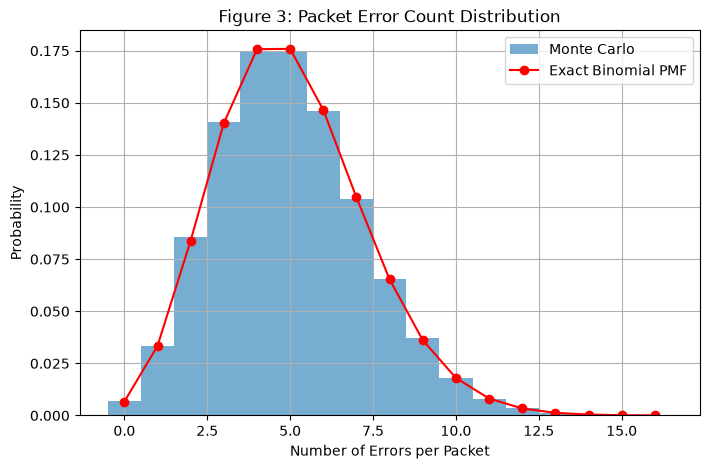

In [19]:

k = np.arange(0, error_counts.max() + 1)

plt.figure(figsize=(8, 5))
plt.hist(error_counts, bins=np.arange(-0.5, k[-1] + 1.5, 1),
         density=True, alpha=0.6, label="Monte Carlo")
plt.plot(k, binom.pmf(k, n_bits, p4), "ro-",
         label="Exact Binomial PMF")

plt.xlabel("Number of Errors per Packet")
plt.ylabel("Probability")
plt.title("Figure 3: Packet Error Count Distribution")
plt.legend()
plt.grid(True)
plt.show()


In [20]:

mean_exact = n_bits * p4
variance_exact = n_bits * p4 * (1 - p4)

mean_sim = np.mean(error_counts)
variance_sim = np.var(error_counts, ddof=1)

print(f"{'Measurement':<15} {'Theoretical':<15} {'Simulated':<15} {'Difference':<15}")
print(f"{'Mean':<15} {mean_exact:<15.6f} {mean_sim:<15.6f} {abs(mean_exact - mean_sim):<15.6f}")
print(f"{'Variance':<15} {variance_exact:<15.6f} {variance_sim:<15.6f} {abs(variance_exact - variance_sim):<15.6f}")


Measurement     Theoretical     Simulated       Difference     
Mean            5.000000        4.999300        0.000700       
Variance        4.975000        5.006670        0.031670       


In [21]:

p_values4 = [0.005, 0.001, 0.0001]

print(f"{'p':<12} {'Exact P(0)':<15} {'Simulated P(0)':<18} {'Difference':<15}")

for p in p_values4:
    counts = packet_errors(n_pkt, n_bits, p, rng_step4)
    exact_p0 = (1 - p)**n_bits
    simulated_p0 = np.mean(counts == 0)
    difference = abs(exact_p0 - simulated_p0)
    print(f"{p:<12.4f} {exact_p0:<15.6f} {simulated_p0:<18.6f} {difference:<15.6f}")


p            Exact P(0)      Simulated P(0)     Difference     
0.0050       0.006654        0.006710           0.000056       
0.0010       0.367695        0.366230           0.001465       
0.0001       0.904833        0.905680           0.000847       


In figure 3, the Binomial probability distribution is compared to the simulated packet error count for 1000-bit packets with a bit error probability of .005. The histogram from the simulation agrees well with the Binomial distribution. It was found that there was little difference between the simulated means (4.999300) and variances (5.006670), and theoretical means (5.000000) and variances (4.975000). These results show good agreement between the simulation and the Binomial distribution.

In addition, three different bit error probabilities (.005, .001, .0001) were used to calculate the exact probability of receiving a clean packet. The simulated probabilities were also found to be close to the theoretical probabilities for all three cases. The probability of receiving a packet with no errors was less than one percent when the bit error probability was set at .005, or .006654. When using this same packet size, it appears that if the bit error probability is reduced to .001 or .0001, then a much higher percentage of clean packets will be received.


## Step 5: The Poisson Approximation

### Part 1: Total Variation Distance

The total variation distance between two probability mass functions is defined as half the sum of the absolute differences between their probabilities.

$$
d_{TV}(P,Q)=\frac{1}{2}\sum_{k=0}^{K}|P(X=k)-Q(X=k)|
$$

For two identical probability distributions, the total variation distance is 0. For two distributions with disjoint support, the total variation distance is 1.


In [22]:
from mp1lib import tv_distance

print(tv_distance([0.5, 0.5], [0.5, 0.5]))
print(tv_distance([1, 0], [0, 1]))

0.0
1.0


In [23]:

from scipy.stats import poisson
from mp1lib import tv_distance

n5 = 1000
p_values5 = [0.5, 0.05, 0.005, 0.001, 0.0005]

print(f"{'p':<12} {'Mean':<12} {'K':<10} {'Poisson Tail':<15}")

for p in p_values5:
    lam = n5 * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    tail = poisson.sf(K, lam)
    print(f"{p:<12.4f} {lam:<12.4f} {K:<10} {tail:<15.3e}")


p            Mean         K          Poisson Tail   
0.5000       500.0000     968        4.573e-77      
0.0500       50.0000      212        1.895e-65      
0.0050       5.0000       70         3.605e-55      
0.0010       1.0000       41         2.681e-52      
0.0005       0.5000       35         2.405e-53      


In [24]:

print(f"{'p':<12} {'TV Distance':<15} {'Poisson Tail':<15}")

for p in p_values5:
    lam = n5 * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n5, p)
    poisson_pmf = poisson.pmf(k, lam)

    tail = poisson.sf(K, lam)
    tv = tv_distance(binomial_pmf, poisson_pmf) + 0.5 * tail

    print(f"{p:<12.4f} {tv:<15.6f} {tail:<15.3e}")


p            TV Distance     Poisson Tail   
0.5000       0.166057        4.573e-77      
0.0500       0.012446        1.895e-65      
0.0050       0.001228        3.605e-55      
0.0010       0.000276        2.681e-52      
0.0005       0.000114        2.405e-53      


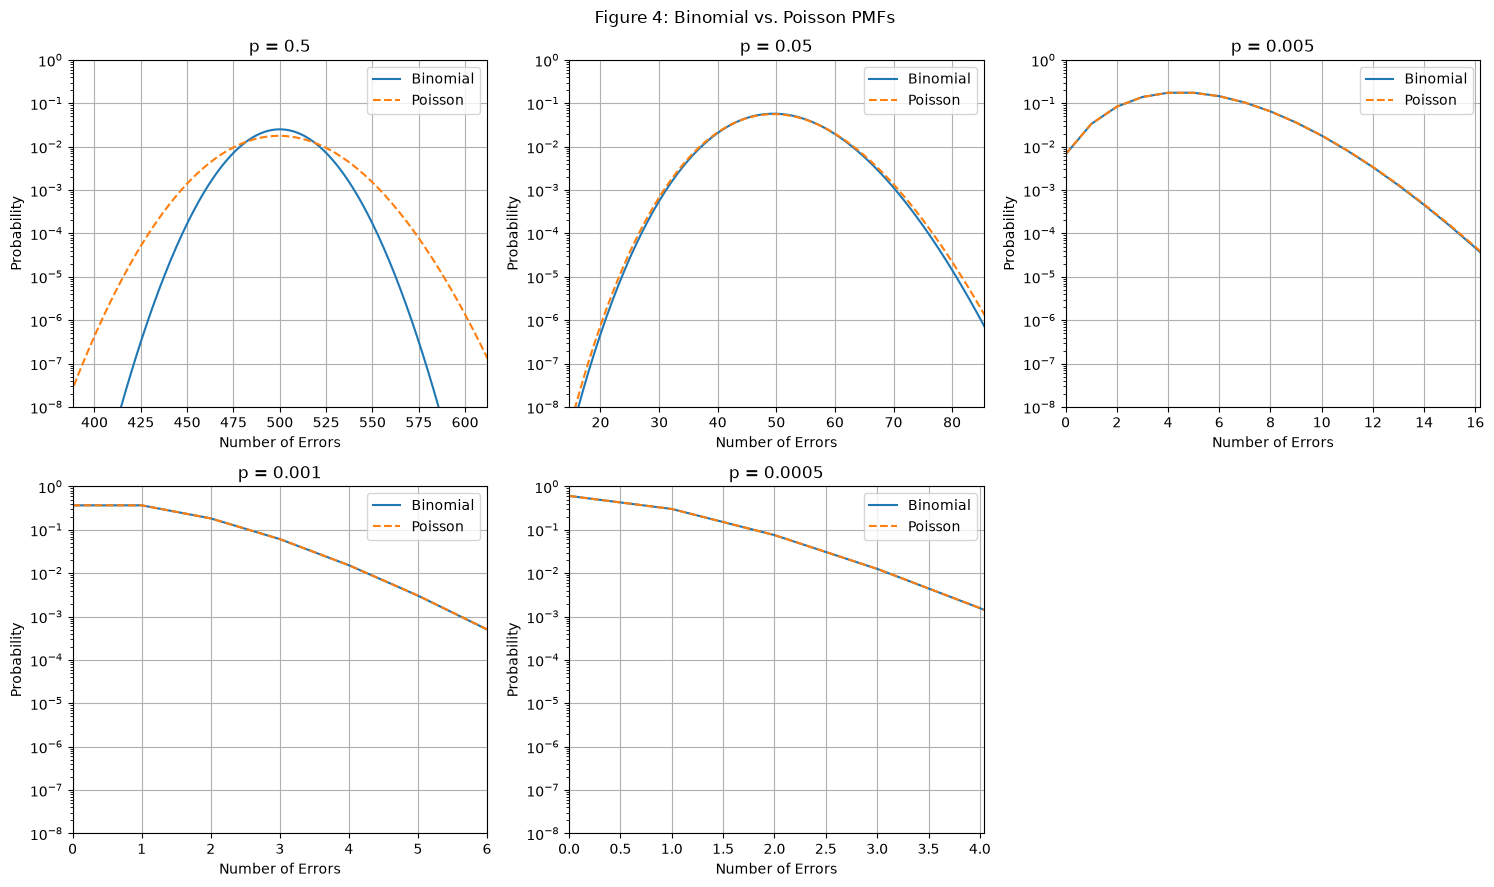

In [25]:

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, p in zip(axes.flat, p_values5):
    lam = n5 * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n5, p)
    poisson_pmf = poisson.pmf(k, lam)

    ax.plot(k, binomial_pmf, label="Binomial")
    ax.plot(k, poisson_pmf, "--", label="Poisson")
    ax.set_yscale("log")
    ax.set_ylim(1e-8, 1)

    ax.set_xlim(max(0, lam - 5 * np.sqrt(lam)), lam + 5 * np.sqrt(lam))
    ax.set_xlabel("Number of Errors")
    ax.set_ylabel("Probability")
    ax.set_title(f"p = {p}")
    ax.legend()
    ax.grid(True)

axes.flat[5].axis("off")

fig.suptitle("Figure 4: Binomial vs. Poisson PMFs")
plt.tight_layout()
plt.show()


In [26]:

p_grid = np.linspace(0.001, 0.1, 100)
tv_grid = []

for p in p_grid:
    lam = n5 * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n5, p)
    poisson_pmf = poisson.pmf(k, lam)

    tail = poisson.sf(K, lam)
    tv = tv_distance(binomial_pmf, poisson_pmf) + 0.5 * tail
    tv_grid.append(tv)

tv_grid = np.array(tv_grid)

print(f"Distance increases across grid: {np.all(np.diff(tv_grid) > 0)}")
print(f"TV at p = 0.001: {tv_grid[0]:.6f}")
print(f"TV at p = 0.1: {tv_grid[-1]:.6f}")


Distance increases across grid: True
TV at p = 0.001: 0.000276
TV at p = 0.1: 0.025508


In [27]:

low = 0.001
high = 0.1

for i in range(50):
    mid = (low + high) / 2
    lam = n5 * mid
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n5, mid)
    poisson_pmf = poisson.pmf(k, lam)

    tail = poisson.sf(K, lam)
    tv = tv_distance(binomial_pmf, poisson_pmf) + 0.5 * tail

    if tv < 0.01:
        low = mid
    else:
        high = mid

p_threshold = (low + high) / 2

print(f"Threshold p: {p_threshold:.6f}")
print(f"Threshold (2 significant figures): {p_threshold:.2g}")
print(f"TV distance at threshold: {tv:.6f}")


Threshold p: 0.040394
Threshold (2 significant figures): 0.04
TV distance at threshold: 0.010000


In [28]:

p_lecam = np.sqrt(0.01 / n5)

print(f"Le Cam threshold: {p_lecam:.6f}")
print(f"Le Cam threshold (2 significant figures): {p_lecam:.2g}")
print(f"Bisection threshold: {p_threshold:.6f}")
print(f"Bisection threshold is larger: {p_threshold > p_lecam}")


Le Cam threshold: 0.003162
Le Cam threshold (2 significant figures): 0.0032
Bisection threshold: 0.040394
Bisection threshold is larger: True


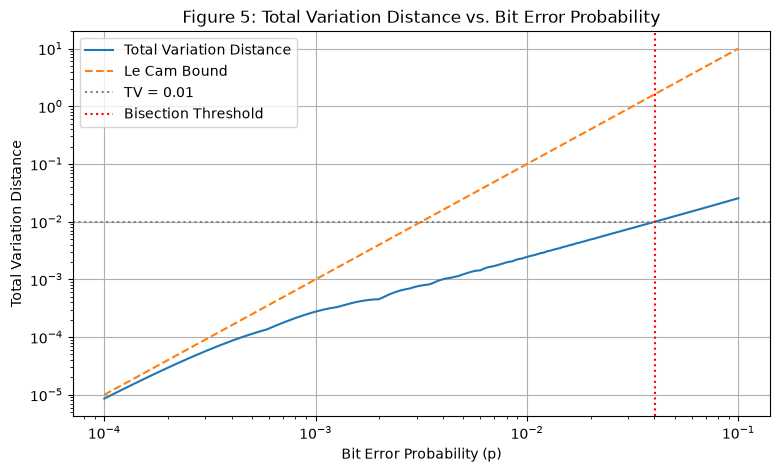

In [29]:

p_plot = np.logspace(-4, -1, 200)
tv_plot = []

for p in p_plot:
    lam = n5 * p
    K = int(np.ceil(lam + 20 * np.sqrt(lam) + 20))
    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n5, p)
    poisson_pmf = poisson.pmf(k, lam)

    tail = poisson.sf(K, lam)
    tv_plot.append(tv_distance(binomial_pmf, poisson_pmf) + 0.5 * tail)

tv_plot = np.array(tv_plot)
lecam_bound = n5 * p_plot**2

plt.figure(figsize=(9, 5))
plt.loglog(p_plot, tv_plot, label="Total Variation Distance")
plt.loglog(p_plot, lecam_bound, "--", label="Le Cam Bound")
plt.axhline(0.01, color="gray", linestyle=":", label="TV = 0.01")
plt.axvline(p_threshold, color="red", linestyle=":", label="Bisection Threshold")
plt.xlabel("Bit Error Probability (p)")
plt.ylabel("Total Variation Distance")
plt.title("Figure 5: Total Variation Distance vs. Bit Error Probability")
plt.legend()
plt.grid(True)
plt.show()


The results from Step 5 illustrate how the Poisson distribution approximates the Binomial distribution as the probability of a single-bit error (p) reduces. The plots in Figure 4 and Figure 5 show that the Total Variation Distance (TVD) between the two distributions is decreasing as p decreases. This illustrates that the probabilities of both distributions are becoming increasingly alike. Utilizing the bisection algorithm, we identified a maximum p value of approximately .04 where TVD < .01; whereas, using Le Cam bounds, we identified a maximum p value of approximately .0032. The bisection threshold is greater than the Le Cam threshold since the latter represents an upper bound for TVD and therefore serves as a more conservative bound. In summary, the Poisson model will be most accurate when n (the number of trials) is great and p (probability of a single trial failing) is small, especially if np (expected failures) is relatively low.


## Step 6: Retransmissions and the Geometric Distribution

### Part 1: Geometric Distribution

T represents the total number of times you will have to send a packet in order for the first one to reach your receiver without being modified, and this is represented as a geometric distribution with a discrete random variable, since every time you send a packet it can either be received successfully or contain errors. Because each transmission is independent and has a constant probability of success, we can use the geometric distribution to calculate how many attempts we would expect before getting an acceptable transmission.

For this project, we will count the number of attempts starting from 1, including the successful attempt. We could also choose to count the number of unsuccessful transmissions (or "failures") starting from 0.

For the convention used in this project, the geometric probability mass function (PMF) is:

$$
P(T=k)=(1-q)^{k-1}q,\qquad k=1,2,3,\ldots
$$

For Step 6, the probability of a successful transmission is $q=0.7$.


In [30]:

test_rng = np.random.default_rng(0)
print(attempts_until_clean(5, 1.0, test_rng))


[1 1 1 1 1]


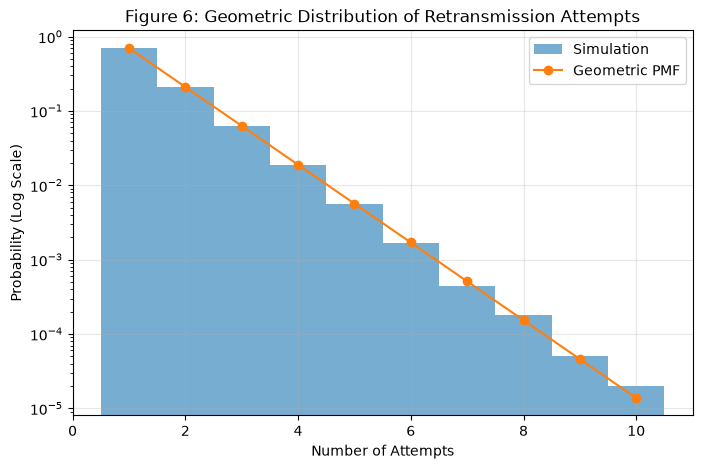

In [31]:

# Step 6: Geometric distribution simulation
rng_step6 = rng.spawn(1)[0]

q6 = 0.7
n_trials6 = 100000

attempts6 = attempts_until_clean(n_trials6, q6, rng_step6)

k = np.arange(1, attempts6.max() + 1)
pmf6 = q6 * (1 - q6)**(k - 1)

plt.figure(figsize=(8, 5))
plt.hist(attempts6, bins=np.arange(0.5, attempts6.max() + 1.5),
         density=True, alpha=0.6, label="Simulation")
plt.plot(k, pmf6, "o-", label="Geometric PMF")

plt.yscale("log")
plt.xlabel("Number of Attempts")
plt.ylabel("Probability (Log Scale)")
plt.title("Figure 6: Geometric Distribution of Retransmission Attempts")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [32]:

# Step 6: Mean and variance comparison
sample_mean6 = np.mean(attempts6)
sample_var6 = np.var(attempts6)

theory_mean6 = 1 / q6
theory_var6 = (1 - q6) / q6**2

print(f"Sample Mean: {sample_mean6:.6f}")
print(f"Theoretical Mean: {theory_mean6:.6f}")
print(f"Mean Difference: {abs(sample_mean6 - theory_mean6):.6f}")

print()

print(f"Sample Variance: {sample_var6:.6f}")
print(f"Theoretical Variance: {theory_var6:.6f}")
print(f"Variance Difference: {abs(sample_var6 - theory_var6):.6f}")


Sample Mean: 1.426080
Theoretical Mean: 1.428571
Mean Difference: 0.002491

Sample Variance: 0.610516
Theoretical Variance: 0.612245
Variance Difference: 0.001729



The theoretical mean and variance of the geometric distribution are calculated using the following formulas:

$$
E[T] = \frac{1}{q} = \frac{1}{0.7} = 1.428571
$$

$$
\mathrm{Var}(T) = \frac{1-q}{q^2} = \frac{0.3}{0.7^2} = 0.612245
$$


In [33]:

# Step 6: Memorylessness test
pairs6 = [(1, 2), (3, 2), (5, 2)]

for m, n in pairs6:
    past_m = attempts6 > m
    past_mn = attempts6 > (m + n)

    conditional_prob = np.sum(past_mn) / np.sum(past_m)
    unconditional_prob = np.mean(attempts6 > n)

    se_conditional = np.sqrt(conditional_prob * (1 - conditional_prob) / np.sum(past_m))
    se_unconditional = np.sqrt(unconditional_prob * (1 - unconditional_prob) / n_trials6)

    print(f"m={m}, n={n}")
    print(f"P(T>{m+n} | T>{m}) = {conditional_prob:.6f}, SE = {se_conditional:.6f}")
    print(f"P(T>{n}) = {unconditional_prob:.6f}, SE = {se_unconditional:.6f}")
    print()


m=1, n=2
P(T>3 | T>1) = 0.090096, SE = 0.001660
P(T>2) = 0.090310, SE = 0.000906

m=3, n=2
P(T>5 | T>3) = 0.088773, SE = 0.005493
P(T>2) = 0.090310, SE = 0.000906

m=5, n=2
P(T>7 | T>5) = 0.105042, SE = 0.019874
P(T>2) = 0.090310, SE = 0.000906



The probability of a link succeeding at the sixth attempt does not increase relative to it succeeding for the first time since every single transmission is an independent event, with the exact same chance of success as all other events, irrespective of whether or not the attempted communications were successful prior to this one. It also makes assumptions about a static environment for the transmission process which are not true in reality where interference from signals, changes in signal strengths, etc. may create dependencies among error rates.


## Step 7: Expectation, Variance, and How Fast Estimates Settle

### Part 1: Running Sample Means

For this step, we will compare the running sample means of the Binomial distribution from Step 4 and the Geometric distribution from Step 6.

For the Binomial distribution, $n=1000$ and $p=0.005$, giving a theoretical mean of:

$$
E[X]=np=1000(0.005)=5
$$

For the Geometric distribution, $q=0.7$, giving a theoretical mean of:

$$
E[T]=\frac{1}{q}=\frac{1}{0.7}\approx1.428571
$$


In [34]:

# Step 7: Set up checkpoints
rng_step7 = rng.spawn(1)[0]

checkpoints7 = np.unique(np.logspace(1, 5, 30).astype(int))
n_runs7 = 200

print("Number of checkpoints:", len(checkpoints7))
print("First checkpoint:", checkpoints7[0])
print("Last checkpoint:", checkpoints7[-1])
print("Number of runs:", n_runs7)


Number of checkpoints: 30
First checkpoint: 10
Last checkpoint: 100000
Number of runs: 200


In [35]:

# Step 7: Running means for 200 independent runs
binomial_means7 = np.zeros((n_runs7, len(checkpoints7)))
geometric_means7 = np.zeros((n_runs7, len(checkpoints7)))

for run in range(n_runs7):
    binomial_sum = 0
    geometric_sum = 0
    previous_n = 0

    for j, N in enumerate(checkpoints7):
        batch_size = N - previous_n

        binomial_samples = packet_errors(batch_size, 1000, 0.005, rng_step7)
        geometric_samples = attempts_until_clean(batch_size, 0.7, rng_step7)

        binomial_sum += np.sum(binomial_samples)
        geometric_sum += np.sum(geometric_samples)

        binomial_means7[run, j] = binomial_sum / N
        geometric_means7[run, j] = geometric_sum / N

        previous_n = N

print("Binomial shape:", binomial_means7.shape)
print("Geometric shape:", geometric_means7.shape)


Binomial shape: (200, 30)
Geometric shape: (200, 30)


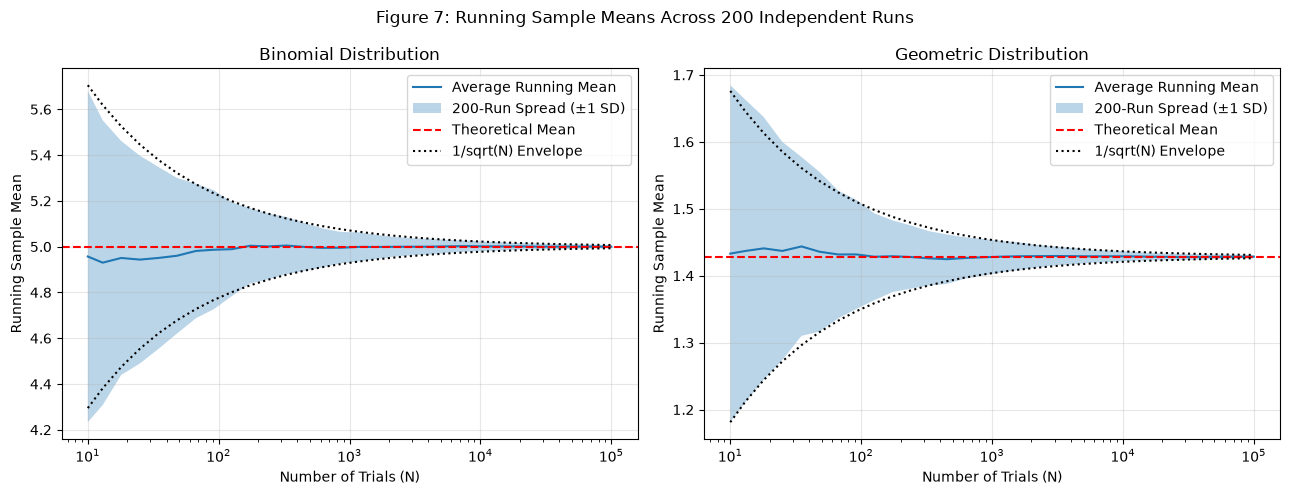

In [36]:

# Step 7: Figure 7
mean_bin7 = np.mean(binomial_means7, axis=0)
std_bin7 = np.std(binomial_means7, axis=0)

mean_geo7 = np.mean(geometric_means7, axis=0)
std_geo7 = np.std(geometric_means7, axis=0)

true_bin7 = 5
true_geo7 = 1 / 0.7

envelope_bin7 = np.sqrt(1000 * 0.005 * 0.995 / checkpoints7)
envelope_geo7 = np.sqrt(((1 - 0.7) / 0.7**2) / checkpoints7)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(checkpoints7, mean_bin7, label="Average Running Mean")
axes[0].fill_between(checkpoints7, mean_bin7 - std_bin7,
                     mean_bin7 + std_bin7, alpha=0.3, label="200-Run Spread (±1 SD)")
axes[0].axhline(true_bin7, color="red", linestyle="--", label="Theoretical Mean")
axes[0].plot(checkpoints7, true_bin7 + envelope_bin7, "k:",
             label="1/sqrt(N) Envelope")
axes[0].plot(checkpoints7, true_bin7 - envelope_bin7, "k:")
axes[0].set_xscale("log")
axes[0].set_xlabel("Number of Trials (N)")
axes[0].set_ylabel("Running Sample Mean")
axes[0].set_title("Binomial Distribution")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(checkpoints7, mean_geo7, label="Average Running Mean")
axes[1].fill_between(checkpoints7, mean_geo7 - std_geo7,
                     mean_geo7 + std_geo7, alpha=0.3, label="200-Run Spread (±1 SD)")
axes[1].axhline(true_geo7, color="red", linestyle="--", label="Theoretical Mean")
axes[1].plot(checkpoints7, true_geo7 + envelope_geo7, "k:",
             label="1/sqrt(N) Envelope")
axes[1].plot(checkpoints7, true_geo7 - envelope_geo7, "k:")
axes[1].set_xscale("log")
axes[1].set_xlabel("Number of Trials (N)")
axes[1].set_ylabel("Running Sample Mean")
axes[1].set_title("Geometric Distribution")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Figure 7: Running Sample Means Across 200 Independent Runs")
plt.tight_layout()
plt.show()


In [37]:

# Step 7: Trials needed for 1% accuracy
tolerance7 = 0.01 * true_bin7

lower7 = mean_bin7 - std_bin7
upper7 = mean_bin7 + std_bin7

within7 = (lower7 >= true_bin7 - tolerance7) & (upper7 <= true_bin7 + tolerance7)

if np.any(within7):
    first_index7 = np.where(within7)[0][0]
    needed_trials7 = checkpoints7[first_index7]
    print("Trials needed:", needed_trials7)
    print("Lower band:", round(lower7[first_index7], 6))
    print("Upper band:", round(upper7[first_index7], 6))
else:
    print("The 200-run band does not fit within 1% at the tested checkpoints.")


Trials needed: 2212
Lower band: 4.956632
Upper band: 5.042075


Figure 7 displays the behavior of the running sample means of the Binomial and Geometric distributions as they approximate the actual means of these two distributions with an increase in trial numbers. The shaded bands represent the spread among 200 different simulations, and decrease as the number of trials increases. These results show that generally, increasing the sample size produces a more consistent estimate. The dotted lines represent the theoretical (1/√N) envelope, and follow approximately the same rate of decline as the observed spread.

For the Binomial distribution, the true mean is 5. Thus, obtaining an estimate that falls within ±1% of 5 requires estimating the mean to be between 4.95 and 5.05. Using the simulated spreads from all 200 runs of this experiment it appears that about 2,212 trials are required for the whole one standard deviation band to be contained entirely within this range. Therefore, there appear to be enough data points to produce a fairly good estimate of the Binomial mean using this experimental design when having at least several thousand trials.


## Step 8: Putting It Together, the Throughput of the Link

### Part 1: Probability of a Clean Packet and Expected Transmissions

For a 1000-bit packet, the probability that the entire packet arrives without any bit errors is:

$$
q=(1-p)^{1000}
$$

Since the number of transmission attempts until the first clean packet follows a geometric distribution, the expected number of transmissions per successfully delivered packet is:

$$
E[T]=\frac{1}{q}=\frac{1}{(1-p)^{1000}}
$$


In [38]:

# Step 8: Expected transmissions
rng_step8 = rng.spawn(1)[0]

p_values8 = np.logspace(-5, -2, 200)
q_values8 = (1 - p_values8)**1000
expected8 = 1 / q_values8

print("First p value:", p_values8[0])
print("Last p value:", p_values8[-1])
print("Expected transmissions at first p:", round(expected8[0], 6))
print("Expected transmissions at last p:", round(expected8[-1], 2))


First p value: 1e-05
Last p value: 0.01
Expected transmissions at first p: 1.01005
Expected transmissions at last p: 23163.57


In [39]:

# Step 8: Simulated transmission points
p_sim8 = np.logspace(-5, -3, 5)
n_sim8 = 10000

sim_means8 = []
sim_se8 = []

for p in p_sim8:
    q = (1 - p)**1000
    attempts = attempts_until_clean(n_sim8, q, rng_step8)

    sim_means8.append(np.mean(attempts))
    sim_se8.append(np.std(attempts, ddof=1) / np.sqrt(n_sim8))

for i in range(len(p_sim8)):
    print(f"p = {p_sim8[i]:.6f}, Mean = {sim_means8[i]:.4f}, SE = {sim_se8[i]:.4f}")


p = 0.000010, Mean = 1.0109, SE = 0.0011
p = 0.000032, Mean = 1.0323, SE = 0.0018
p = 0.000100, Mean = 1.1027, SE = 0.0034
p = 0.000316, Mean = 1.3713, SE = 0.0070
p = 0.001000, Mean = 2.7536, SE = 0.0219


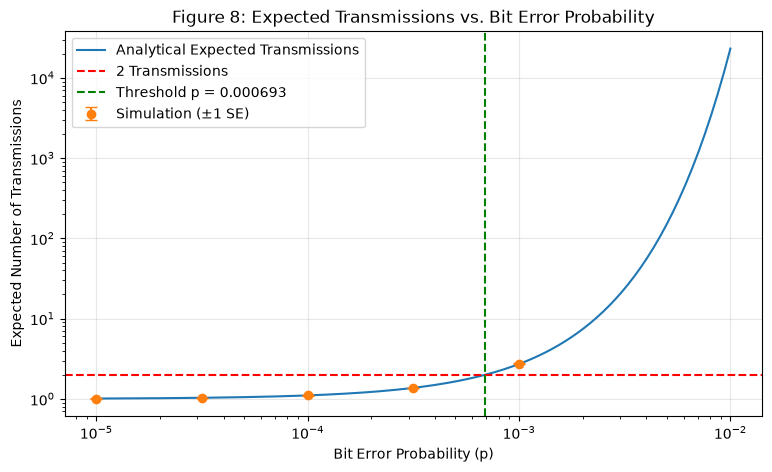

Threshold where E[T] = 2: p = 0.00069291


In [40]:

# Step 8: Figure 8
p_two8 = 1 - 2**(-1/1000)

plt.figure(figsize=(9, 5))

plt.plot(p_values8, expected8, label="Analytical Expected Transmissions")
plt.errorbar(p_sim8, sim_means8, yerr=sim_se8, fmt="o",
             capsize=4, label="Simulation (±1 SE)")

plt.axhline(2, color="red", linestyle="--", label="2 Transmissions")
plt.axvline(p_two8, color="green", linestyle="--",
            label=f"Threshold p = {p_two8:.6f}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Bit Error Probability (p)")
plt.ylabel("Expected Number of Transmissions")
plt.title("Figure 8: Expected Transmissions vs. Bit Error Probability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Threshold where E[T] = 2: p = {p_two8:.8f}")


The analytical curve can be extended to an error probability of \(p=0.01\) because the formula allows us to calculate the expected number of transmission attempts directly, even when approximately 23,164 attempts are required on average to successfully deliver a single packet, without having to perform computationally expensive simulations.

In [41]:

# Step 8: Goodput for two packet lengths
goodput_1000 = (1 - p_values8)**1000
goodput_100 = (1 - p_values8)**100

p_90_1000 = 1 - 0.9**(1/1000)
p_90_100 = 1 - 0.9**(1/100)

print(f"1000-bit packet, 90% goodput threshold: p = {p_90_1000:.8f}")
print(f"100-bit packet, 90% goodput threshold: p = {p_90_100:.8f}")


1000-bit packet, 90% goodput threshold: p = 0.00010535
100-bit packet, 90% goodput threshold: p = 0.00105305


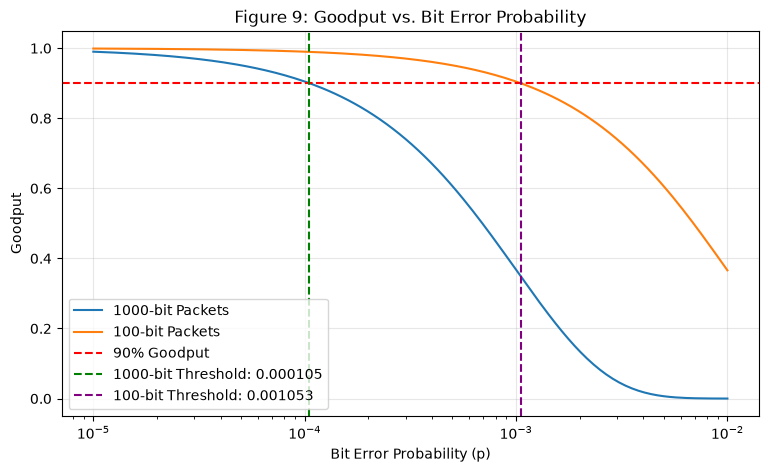

In [42]:

# Step 8: Figure 9
plt.figure(figsize=(9, 5))

plt.plot(p_values8, goodput_1000, label="1000-bit Packets")
plt.plot(p_values8, goodput_100, label="100-bit Packets")

plt.axhline(0.9, color="red", linestyle="--", label="90% Goodput")
plt.axvline(p_90_1000, color="green", linestyle="--",
            label=f"1000-bit Threshold: {p_90_1000:.6f}")
plt.axvline(p_90_100, color="purple", linestyle="--",
            label=f"100-bit Threshold: {p_90_100:.6f}")

plt.xscale("log")
plt.xlabel("Bit Error Probability (p)")
plt.ylabel("Goodput")
plt.title("Figure 9: Goodput vs. Bit Error Probability")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


The goodput shown in figure 9 for a communication link decreases as the probability of a bit error (bit_error) increases. To get a goodput greater than 90% with a 1000-bit data packet, the probability of a bit error (bit_error) must remain below approximately 0.00010535. However, if you reduce the number of bits in each packet from 1000 to 100, then your communication system could tolerate a much higher probability of a bit error (approximately 0.00105305), and still obtain the same level of goodput. This happens since there are many fewer chances for an error to occur on a short packet. As such, the length of the data packet may need to be decreased to increase the goodput performance of a communications system when the frequency of bit errors is high.

Bonus A: Geometric tail
  k          exact     simulation     difference             SE
  1   3.000000e-01   2.991300e-01     -8.700e-04      1.449e-03
  2   9.000000e-02   9.038000e-02     +3.800e-04      9.050e-04
  3   2.700000e-02   2.694000e-02     -6.000e-05      5.126e-04
  4   8.100000e-03   8.360000e-03     +2.600e-04      2.834e-04
  5   2.430000e-03   2.390000e-03     -4.000e-05      1.557e-04
  6   7.290000e-04   6.700000e-04     -5.900e-05      8.535e-05
  7   2.187000e-04   1.900000e-04     -2.870e-05      4.676e-05
  8   6.561000e-05   4.000000e-05     -2.561e-05      2.561e-05


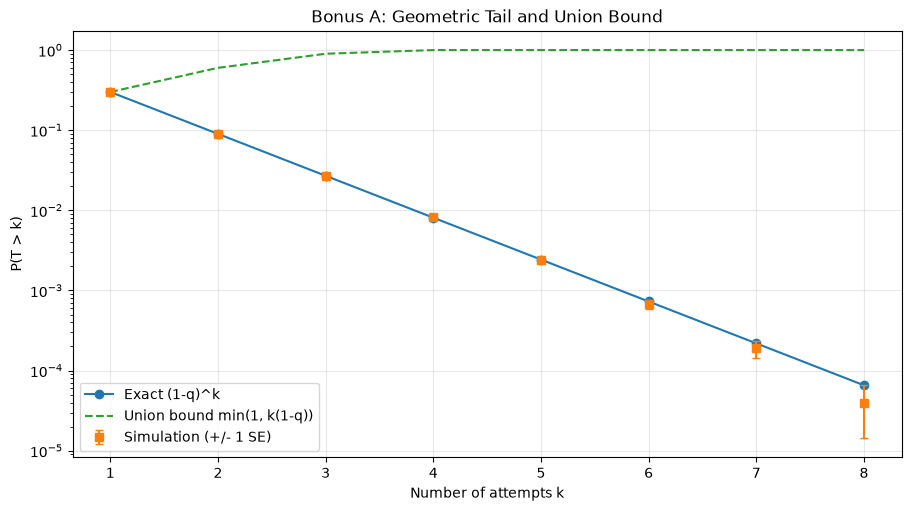

In [43]:
rng_bonusA = rng.spawn(1)[0]

q_bonusA = 0.7
N_bonusA = 100_000
k_values_bonusA = np.arange(1, 9)

attempts_bonusA = attempts_until_clean(N_bonusA, q_bonusA, rng_bonusA)
exact_tail_bonusA = (1.0 - q_bonusA) ** k_values_bonusA
simulated_tail_bonusA = np.array(
    [np.mean(attempts_bonusA > k) for k in k_values_bonusA]
)
tail_se_bonusA = np.sqrt(
    exact_tail_bonusA * (1.0 - exact_tail_bonusA) / N_bonusA
)
union_bound_bonusA = np.minimum(
    1.0, k_values_bonusA * (1.0 - q_bonusA)
)

print("Bonus A: Geometric tail")
print(
    f"{'k':>3s} {'exact':>14s} {'simulation':>14s} "
    f"{'difference':>14s} {'SE':>14s}"
)
for k, exact, simulation, se in zip(
    k_values_bonusA,
    exact_tail_bonusA,
    simulated_tail_bonusA,
    tail_se_bonusA,
):
    print(
        f"{k:3d} {exact:14.6e} {simulation:14.6e} "
        f"{simulation - exact:+14.3e} {se:14.3e}"
    )

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.semilogy(
    k_values_bonusA,
    exact_tail_bonusA,
    "o-",
    label="Exact (1-q)^k",
)
ax.errorbar(
    k_values_bonusA,
    simulated_tail_bonusA,
    yerr=tail_se_bonusA,
    fmt="s",
    capsize=3,
    label="Simulation (+/- 1 SE)",
)
ax.semilogy(
    k_values_bonusA,
    union_bound_bonusA,
    "--",
    label="Union bound min(1, k(1-q))",
)
ax.set_xlabel("Number of attempts k")
ax.set_ylabel("P(T > k)")
ax.set_title("Bonus A: Geometric Tail and Union Bound")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


Bonus B numerical integer optimum L: 653
Bonus B integer goodput: 0.8793999680580221
Bonus B continuous optimum: 652.7558768329615
Bonus B continuous goodput: 0.8793999763461476

Bonus B simulation near the optimum
     L       theory G   simulation G     difference           SE
   651     0.87939955     0.88082669     +1.427e-03    6.893e-04
   652     0.87939990     0.87871327     -6.866e-04    7.014e-04
   653     0.87939997     0.88049097     +1.091e-03    6.914e-04
   654     0.87939976     0.87955586     +1.561e-04    6.997e-04
   655     0.87939928     0.87975048     +3.512e-04    7.013e-04


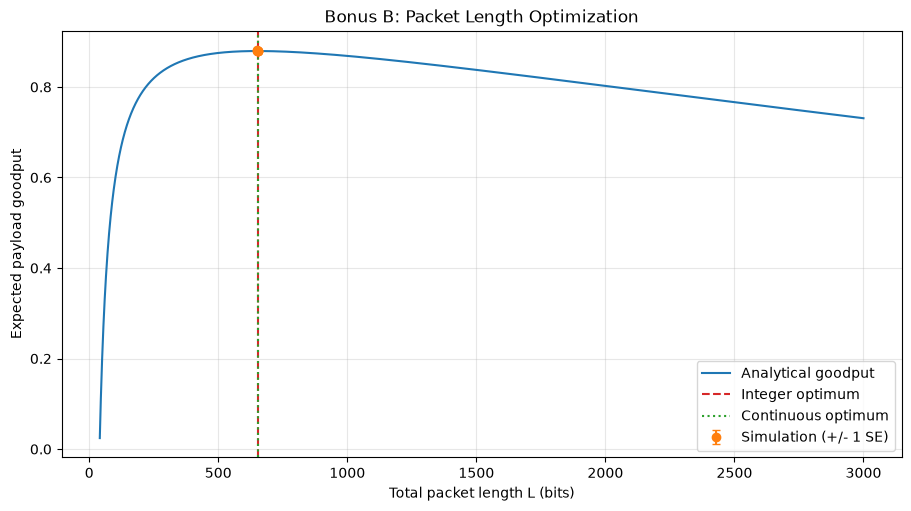

In [44]:
rng_bonusB = rng.spawn(1)[0]

p_bonusB = 1e-4
header_bonusB = 40
length_grid_bonusB = np.arange(header_bonusB + 1, 3001)

clean_probability_bonusB = (1.0 - p_bonusB) ** length_grid_bonusB
goodput_grid_bonusB = (
    (length_grid_bonusB - header_bonusB) / length_grid_bonusB
    * clean_probability_bonusB
)

integer_index_bonusB = int(np.argmax(goodput_grid_bonusB))
integer_optimum_bonusB = int(length_grid_bonusB[integer_index_bonusB])
integer_goodput_bonusB = float(goodput_grid_bonusB[integer_index_bonusB])

a_bonusB = -np.log1p(-p_bonusB)
continuous_optimum_bonusB = (
    header_bonusB
    + np.sqrt(header_bonusB**2 + 4.0 * header_bonusB / a_bonusB)
) / 2.0
continuous_goodput_bonusB = (
    (continuous_optimum_bonusB - header_bonusB) / continuous_optimum_bonusB
    * (1.0 - p_bonusB) ** continuous_optimum_bonusB
)

print("Bonus B numerical integer optimum L:", integer_optimum_bonusB)
print("Bonus B integer goodput:", integer_goodput_bonusB)
print("Bonus B continuous optimum:", continuous_optimum_bonusB)
print("Bonus B continuous goodput:", continuous_goodput_bonusB)

candidate_lengths_bonusB = np.arange(
    integer_optimum_bonusB - 2,
    integer_optimum_bonusB + 3,
)
N_bonusB = 100_000
simulated_goodputs_bonusB = []
simulated_goodput_se_bonusB = []

print("\nBonus B simulation near the optimum")
print(
    f"{'L':>6s} {'theory G':>14s} {'simulation G':>14s} "
    f"{'difference':>14s} {'SE':>12s}"
)
for length_bonusB in candidate_lengths_bonusB:
    q_bonusB = (1.0 - p_bonusB) ** length_bonusB
    attempts_bonusB = attempts_until_clean(N_bonusB, q_bonusB, rng_bonusB)
    mean_attempts_bonusB = attempts_bonusB.mean()
    variance_attempts_bonusB = attempts_bonusB.var(ddof=1)
    mean_attempts_se_bonusB = np.sqrt(
        variance_attempts_bonusB / N_bonusB
    )
    payload_fraction_bonusB = (
        length_bonusB - header_bonusB
    ) / length_bonusB
    theory_goodput_bonusB = payload_fraction_bonusB * q_bonusB
    simulation_goodput_bonusB = (
        payload_fraction_bonusB / mean_attempts_bonusB
    )
    goodput_se_bonusB = (
        payload_fraction_bonusB
        / mean_attempts_bonusB**2
        * mean_attempts_se_bonusB
    )
    simulated_goodputs_bonusB.append(simulation_goodput_bonusB)
    simulated_goodput_se_bonusB.append(goodput_se_bonusB)
    print(
        f"{length_bonusB:6d} {theory_goodput_bonusB:14.8f} "
        f"{simulation_goodput_bonusB:14.8f} "
        f"{simulation_goodput_bonusB - theory_goodput_bonusB:+14.3e} "
        f"{goodput_se_bonusB:12.3e}"
    )

simulated_goodputs_bonusB = np.array(simulated_goodputs_bonusB)
simulated_goodput_se_bonusB = np.array(simulated_goodput_se_bonusB)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.plot(
    length_grid_bonusB,
    goodput_grid_bonusB,
    label="Analytical goodput",
)
ax.errorbar(
    candidate_lengths_bonusB,
    simulated_goodputs_bonusB,
    yerr=simulated_goodput_se_bonusB,
    fmt="o",
    capsize=3,
    label="Simulation (+/- 1 SE)",
)
ax.axvline(
    integer_optimum_bonusB,
    color="tab:red",
    linestyle="--",
    label="Integer optimum",
)
ax.axvline(
    continuous_optimum_bonusB,
    color="tab:green",
    linestyle=":",
    label="Continuous optimum",
)
ax.set_xlabel("Total packet length L (bits)")
ax.set_ylabel("Expected payload goodput")
ax.set_title("Bonus B: Packet Length Optimization")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


In [45]:
end_time = time.time()
print(f"Total runtime: {end_time - start_time:.2f} seconds")

Total runtime: 13.22 seconds


Demo:
https://youtu.be/o3D53K3Oy5o